<a href="https://colab.research.google.com/github/Ondor-R/BigData-Tugas_Minggu07/blob/main/Big_Data_Tugas_Minggu_07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Install MongoDB

In [ ]:
%%bash
apt-get install -y -q gnupg curl > /dev/null
curl -fsSL https://www.mongodb.org/static/pgp/server-8.0.asc | gpg --dearmor -o /usr/share/keyrings/mongodb-server-8.0.gpg --yes
echo "deb [signed-by=/usr/share/keyrings/mongodb-server-8.0.gpg] https://repo.mongodb.org/apt/ubuntu $(lsb_release -cs)/mongodb-org/8.0 multiverse" > /etc/apt/sources.list.d/mongodb-org-8.0.list
apt-get update -q
apt-get install -y -q mongodb-org-server

Hit:1 https://cli.github.com/packages stable InRelease
Hit:2 https://repo.mongodb.org/apt/ubuntu noble/mongodb-org/8.0 InRelease
Get:3 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:5 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:8 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Get:10 http://security.ubuntu.com/ubuntu noble-security/restricted amd64 Packages [2,122 kB]
Get:11 http://security.ubuntu.com/ubuntu noble-security/universe amd64 Packages [1,548 kB]
Get:12 http://security.ubuntu.com/ubuntu noble-security/main amd64 Packages [1,409 kB]
Fetched 5,205 kB in 2s (2,224 kB/s)
Reading package lists...
Reading package lists...
Building dependency tree...
Reading state info

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


Starting server di background

In [ ]:
%%bash
mkdir -p /data/db
mongod --dbpath /data/db --bind_ip 127.0.0.1 --fork --logpath /tmp/mongod.log
sleep 3
tail -n 3 /tmp/mongod.log

about to fork child process, waiting until server is ready for connections.
forked process: 47259
ERROR: child process failed, exited with 1
To see additional information in this output, start without the "--fork" option.
{"t":{"$date":"2026-10-13T10:41:48.965+00:00"},"s":"I",  "c":"CONTROL",  "id":20565,   "ctx":"initandlisten","msg":"Now exiting"}
{"t":{"$date":"2026-10-13T10:41:48.965+00:00"},"s":"I",  "c":"CONTROL",  "id":8423404, "ctx":"initandlisten","msg":"mongod shutdown complete","attr":{"Summary of time elapsed":{"Statistics":{"Enter terminal shutdown":"0 ms","Step down the replication coordinator for shutdown":"0 ms","Time spent in quiesce mode":"0 ms","Shut down FLE Crud subsystem":"0 ms","Shut down MirrorMaestro":"0 ms","Shut down WaitForMajorityService":"0 ms","Shut down the global connection pool":"0 ms","Shut down the replica set monitor":"0 ms","Shut down the migration util executor":"0 ms","Shut down the TTL monitor":"0 ms","Shut down expired pre-images and documents 

Verify MongoDBny

In [ ]:
from pymongo import MongoClient
client = MongoClient("mongodb://localhost:27017/", serverSelectionTimeoutMS=3000)
print(client.admin.command("ping"))  # {'ok': 1.0}

{'ok': 1.0}


In [ ]:
!pip install kagglehub[pandas-datasets] pyspark pymongo vaderSentiment scikit-learn pandas matplotlib seaborn -q

import time
import re
import pandas as pd
import numpy as np
from pymongo import MongoClient
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

import pyspark
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, lower, regexp_replace, udf, length, log1p
from pyspark.sql.types import DoubleType, ArrayType, FloatType, StructType, StructField
from pyspark.ml.feature import Tokenizer, StopWordsRemover, HashingTF, IDF, VectorAssembler
from pyspark.ml.classification import LinearSVC
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, BinaryClassificationEvaluator
from pyspark.ml import Pipeline

print(f"PySpark Version: {pyspark.__version__}")

PySpark Version: 4.0.4


In [ ]:
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "CEAS_08.csv"

# Load the latest version
df_raw = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "naserabdullahalam/phishing-email-dataset",
  file_path,
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

print("First 5 records:", df_raw.head())

/tmp/ipykernel_611/792289175.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df_raw = kagglehub.load_dataset(


Using Colab cache for faster access to the 'phishing-email-dataset' dataset.
First 5 records:                                               sender  \
0                   Young Esposito <Young@iworld.de>   
1                       Mok <ipline's1983@icable.ph>   
2  Daily Top 10 <Karmandeep-opengevl@universalnet...   
3                 Michael Parker <ivqrnai@pobox.com>   
4  Gretchen Suggs <externalsep1@loanofficertool.com>   

                                         receiver  \
0                     user4@gvc.ceas-challenge.cc   
1                   user2.2@gvc.ceas-challenge.cc   
2                   user2.9@gvc.ceas-challenge.cc   
3  SpamAssassin Dev <xrh@spamassassin.apache.org>   
4                   user2.2@gvc.ceas-challenge.cc   

                              date  \
0  Tue, 05 Aug 2008 16:31:02 -0700   
1  Tue, 05 Aug 2008 18:31:03 -0500   
2  Tue, 05 Aug 2008 20:28:00 -1200   
3  Tue, 05 Aug 2008 17:31:20 -0600   
4  Tue, 05 Aug 2008 19:31:21 -0400   

                     

In [ ]:
df_raw = df_raw.dropna(subset=["label"]).reset_index(drop=True)

# Mengisi nilai kosong pada subject dan body agar tidak error saat digabungkan
df_raw["subject"] = df_raw["subject"].fillna("")
df_raw["body"] = df_raw["body"].fillna("")

# Menggabungkan kolom subject dan body menjadi satu kolom teks utuh
df_raw["text"] = df_raw["subject"].astype(str) + " " + df_raw["body"].astype(str)

# Memastikan label berbentuk float (1.0 atau 0.0) sesuai kebutuhan PySpark MLlib
df_raw["label"] = df_raw["label"].astype(float)

# Memilih hanya kolom text dan label untuk tahapan Spark berikutnya
df_raw = df_raw[["text", "label"]]

print(f"\nBerhasil memproses {len(df_raw)} baris data.")

# Simpan & Ambil dari MongoDB (Arsitektur NoSQL)
MONGO_URI = "mongodb://localhost:27017/"
USE_MONGODB = False
try:
    client = MongoClient(MONGO_URI, serverSelectionTimeoutMS=3000)
    client.admin.command("ping")
    USE_MONGODB = True
except Exception as e:
    print(f"MongoDB not reachable ({e}). Using local DataFrame.")

if USE_MONGODB:
    db = client["cybersecurity_db"]
    collection = db["phishing_emails"]

    collection.delete_many({})
    collection.insert_many(df_raw.to_dict("records"))
    print(f"Berhasil menyimpan {collection.count_documents({})} dokumen ke MongoDB.")

    data_from_mongo = list(collection.find({}, {"_id": 0, "text": 1, "label": 1}))
    df_pandas = pd.DataFrame(data_from_mongo)
else:
    print("Mode lokal: Memuat DataFrame langsung tanpa MongoDB...")
    df_pandas = df_raw

# Inisialisasi SparkSession dan Pemuatan ke PySpark DataFrame
spark = SparkSession.builder \
    .appName("Phishing_Sentiment_Spark_SVM") \
    .master("local[*]") \
    .config("spark.driver.memory", "4g") \
    .getOrCreate()

spark_df = spark.createDataFrame(df_pandas)
spark_df.cache()

print(f"\nTotal baris di Spark DataFrame: {spark_df.count()}")
spark_df.show(5, truncate=80)


Berhasil memproses 39154 baris data.
Berhasil menyimpan 39154 dokumen ke MongoDB.

Total baris di Spark DataFrame: 39154
+--------------------------------------------------------------------------------+-----+
|                                                                            text|label|
+--------------------------------------------------------------------------------+-----+
|Never agree to be a loser Buck up, your troubles caused by small dimension wi...|  1.0|
|Befriend Jenna Jameson \nUpgrade your sex and pleasures with these techniques...|  1.0|
|CNN.com Daily Top 10 >+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+...|  1.0|
|Re: svn commit: r619753 - in /spamassassin/trunk: lib/Mail/SpamAssassin/PerMs...|  0.0|
|SpecialPricesPharmMoreinfo \nWelcomeFastShippingCustomerSupport\nhttp://7iwfn...|  1.0|
+--------------------------------------------------------------------------------+-----+
only showing top 5 rows


In [ ]:
start_prep = time.time()

# UDF Ekstraksi Fitur Sentimen VADER & Urgensi (pada teks asli sebelum di-lowercase)
analyzer = SentimentIntensityAnalyzer()

# Satu UDF mengembalikan compound, neg, dan pos sekaligus (VADER hanya dipanggil 1x per email)
vader_schema = StructType([
    StructField("compound", DoubleType()),
    StructField("neg", DoubleType()),
    StructField("pos", DoubleType()),
])

def vader_scores(text):
    if not text:
        return (0.0, 0.0, 0.0)
    s = analyzer.polarity_scores(str(text))
    return (float(s["compound"]), float(s["neg"]), float(s["pos"]))

def extract_urgency_caps(text):
    if not text:
        return 0.0
    words = str(text).split()
    return float(sum(1 for w in words if w.isupper() and len(w) > 1))

def extract_exclamation_count(text):
    if not text:
        return 0.0
    return float(str(text).count("!"))

vader_udf = udf(vader_scores, vader_schema)
caps_udf = udf(extract_urgency_caps, DoubleType())
excl_udf = udf(extract_exclamation_count, DoubleType())

# Tambahkan kolom fitur sentimen & metadata urgensi
# Fitur hitungan/panjang diberi log1p agar skalanya sebanding dengan fitur VADER dan TF-IDF
df_features = spark_df \
    .withColumn("vader", vader_udf(col("text"))) \
    .withColumn("vader_compound", col("vader.compound")) \
    .withColumn("vader_neg", col("vader.neg")) \
    .withColumn("vader_pos", col("vader.pos")) \
    .drop("vader") \
    .withColumn("caps_count", log1p(caps_udf(col("text")))) \
    .withColumn("excl_count", log1p(excl_udf(col("text")))) \
    .withColumn("body_length", log1p(length(col("text")).cast(DoubleType())))

# Pembersihan Teks (HTML removal, Noise Filtering, Lowercasing)
df_cleaned = df_features \
    .withColumn("clean_text", regexp_replace(col("text"), r"<[^>]+>", " ")) \
    .withColumn("clean_text", lower(col("clean_text"))) \
    .withColumn("clean_text", regexp_replace(col("clean_text"), r"http\S+|www\S+", " url ")) \
    .withColumn("clean_text", regexp_replace(col("clean_text"), r"[^a-z\s]", " ")) \
    .withColumn("clean_text", regexp_replace(col("clean_text"), r"\s+", " "))

# Split data sebelum fitting TF-IDF agar tidak terjadi data leakage
train_df, test_df = df_cleaned.randomSplit([0.8, 0.2], seed=42)

# Pipeline Tokenization, Stopword Removal, dan TF-IDF (fit hanya pada data latih)
tokenizer = Tokenizer(inputCol="clean_text", outputCol="tokens")
remover = StopWordsRemover(inputCol="tokens", outputCol="filtered_tokens")
hashingTF = HashingTF(inputCol="filtered_tokens", outputCol="raw_tfidf", numFeatures=5000)
idf = IDF(inputCol="raw_tfidf", outputCol="tfidf_features")

prep_pipeline = Pipeline(stages=[tokenizer, remover, hashingTF, idf])
prep_model = prep_pipeline.fit(train_df)

train_t = prep_model.transform(train_df).cache()
test_t = prep_model.transform(test_df).cache()

# Trigger action untuk menghitung waktu eksekusi
n_train = train_t.count()
n_test = test_t.count()
print(f"Praproses & Ekstraksi Fitur selesai dalam {time.time() - start_prep:.2f} detik "
      f"(train: {n_train} baris, test: {n_test} baris).")

Praproses & Ekstraksi Fitur selesai dalam 968.79 detik (train: 31441 baris, test: 7713 baris).


In [ ]:
# Data sudah di-split (80/20, seed=42) dan TF-IDF sudah di-fit hanya pada data latih
# pada sel praproses sebelumnya, jadi di sini langsung memakai train_t dan test_t.

# Mendefinisikan 3 Skenario Fitur (Ablation Test)
numeric_cols = ["vader_compound", "vader_neg", "vader_pos", "caps_count", "excl_count", "body_length"]

scenarios = {
    "1. Without Sentiment (TF-IDF Only)": ["tfidf_features"],
    "2. Only Sentiment (VADER + Urgency)": numeric_cols,
    "3. Combined Features (TF-IDF + VADER)": ["tfidf_features"] + numeric_cols
}

# Evaluator dibuat sekali di luar loop
acc_eval = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="accuracy")
prec_eval = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="weightedPrecision")
rec_eval = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="weightedRecall")
f1_eval = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="f1")
auc_eval = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderROC")

results = []
confusion = {}

for name, feature_cols in scenarios.items():
    t0 = time.time()
    assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")
    train_ready = assembler.transform(train_t)
    test_ready = assembler.transform(test_t)

    # Pelatihan SVM di PySpark MLlib (LinearSVC)
    svm = LinearSVC(featuresCol="features", labelCol="label", maxIter=50, regParam=0.1)
    svm_model = svm.fit(train_ready)
    predictions = svm_model.transform(test_ready)

    cm = (predictions.groupBy("label", "prediction").count().toPandas()
          .pivot(index="label", columns="prediction", values="count")
          .reindex(index=[0.0, 1.0], columns=[0.0, 1.0]).fillna(0).astype(int))
    confusion[name] = cm

    # Evaluasi Metrik (Accuracy, Precision, Recall, F1, AUC-ROC)
    acc = acc_eval.evaluate(predictions) * 100
    prec = prec_eval.evaluate(predictions) * 100
    rec = rec_eval.evaluate(predictions) * 100
    f1 = f1_eval.evaluate(predictions) * 100
    auc = auc_eval.evaluate(predictions)
    exec_time = time.time() - t0

    results.append({
        "Scenario": name,
        "Accuracy (%)": round(acc, 2),
        "Precision (%)": round(prec, 2),
        "Recall (%)": round(rec, 2),
        "F1-Score (%)": round(f1, 2),
        "AUC-ROC": round(auc, 4),
        "Time (s)": round(exec_time, 2)
    })

results_df = pd.DataFrame(results)
print("\n=== HASIL EKSPERIMEN REPLIKASI PARSIAL (SVM + VADER) ===")
print(results_df.to_string(index=False))


=== HASIL EKSPERIMEN REPLIKASI PARSIAL (SVM + VADER) ===
                             Scenario  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)  AUC-ROC  Time (s)
   1. Without Sentiment (TF-IDF Only)         98.64          98.66       98.64         98.64   0.9986     31.02
  2. Only Sentiment (VADER + Urgency)         82.68          82.74       82.68         82.70   0.8973     21.01
3. Combined Features (TF-IDF + VADER)         98.82          98.83       98.82         98.82   0.9986     27.42


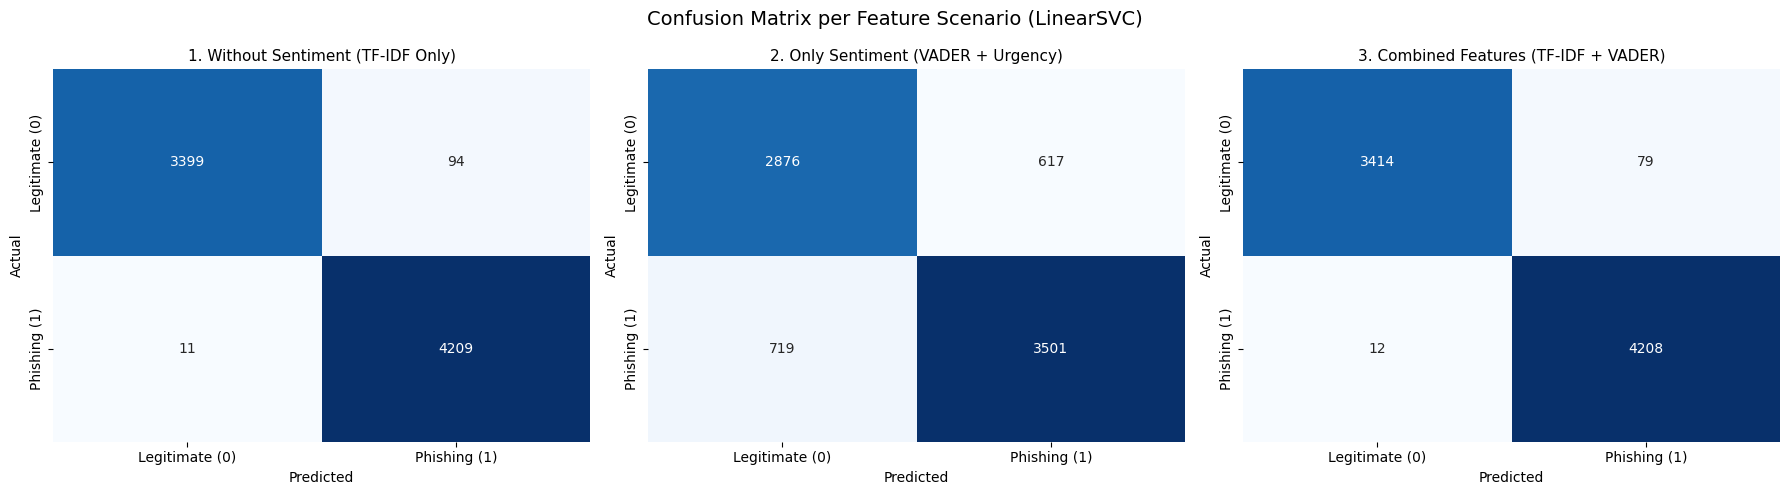

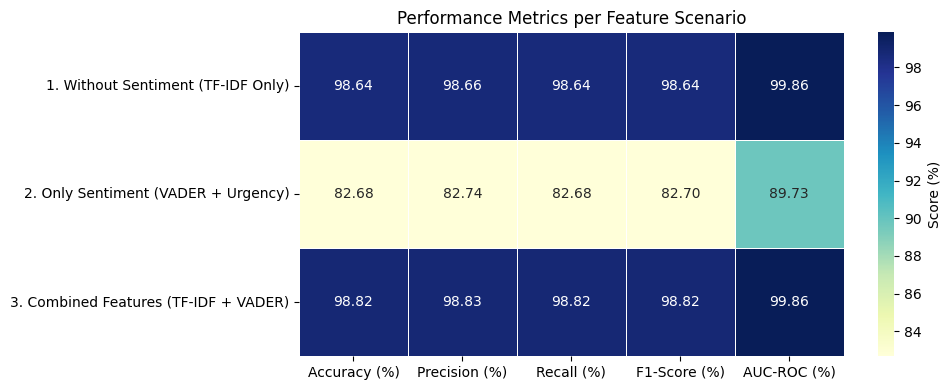

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

labels = ["Legitimate (0)", "Phishing (1)"]

# Heatmap 1: confusion matrix per scenario
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, cm) in zip(axes, confusion.items()):
    sns.heatmap(cm.values, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(name, fontsize=11)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.suptitle("Confusion Matrix per Feature Scenario (LinearSVC)", fontsize=14)
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

# Heatmap 2: metric comparison across scenarios
metrics_df = results_df.set_index("Scenario")[
    ["Accuracy (%)", "Precision (%)", "Recall (%)", "F1-Score (%)", "AUC-ROC"]].copy()
metrics_df["AUC-ROC"] = metrics_df["AUC-ROC"] * 100  # same 0-100 scale as the others
metrics_df = metrics_df.rename(columns={"AUC-ROC": "AUC-ROC (%)"})

plt.figure(figsize=(10, 4))
sns.heatmap(metrics_df, annot=True, fmt=".2f", cmap="YlGnBu", linewidths=0.5,
            cbar_kws={"label": "Score (%)"})
plt.title("Performance Metrics per Feature Scenario")
plt.ylabel("")
plt.tight_layout()
plt.savefig("metrics_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()